<a href="https://colab.research.google.com/github/bidallei/MIAAD-UACJ/blob/main/SARIMA_RutaAcompanada_AlvaroHernandez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sesión 9 · De ARIMA a SARIMA

## Ruta acompañada

Este cuaderno explica cómo incorporar una estacionalidad repetitiva dentro de ARIMA. Trabajaremos con los totales mensuales de pasajeros internacionales entre 1949 y 1960, expresados en miles de pasajeros.

La pregunta central es:

> ¿Qué parte de la serie depende de los meses recientes y qué parte depende del mismo mes de años anteriores?

**Producto:** cuaderno ejecutado y ficha de decisión de una página.

* Asignatura: Métodos para Pronóstico y Analítica Avanzada
* Profesor: Mtro. César Alonso Rivas Flores
* Alumno: **Álvaro Hernández Jarquín**
* Matrícula: 263150
* Fecha de entrega: 2 de noviembre de 2026




### Objetivos

Al terminar podrás:

1. distinguir la parte regular y la parte estacional de SARIMA;
2. interpretar los parámetros `(p,d,q)(P,D,Q,m)`;
3. aplicar una diferencia estacional sin confundirla con una primera diferencia;
4. comparar SARIMA con referentes y métodos ya estudiados;
5. justificar una elección mediante validación y residuos.

La serie procede del conjunto `AirPassengers` del paquete `datasets` de R. Fuente: https://search.r-project.org/R/refmans/datasets/html/AirPassengers.html

## 0. Preparación

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

AZUL = "#007FA3"
NARANJA = "#E57200"
VERDE = "#4F8F3A"
ROJO = "#C4473A"

In [ ]:
ARCHIVO = Path("Datos_Sesion_9_Pasajeros_Aereos_1949_1960.csv")

if not ARCHIVO.exists():
    try:
        from google.colab import files
        print("Carga el archivo CSV proporcionado para la sesión")
        subidos = files.upload()
        ARCHIVO = Path(next(iter(subidos)))
    except Exception as exc:
        raise FileNotFoundError("No se encontró el archivo de datos.") from exc

datos = pd.read_csv(ARCHIVO, parse_dates=["fecha"])
serie = (datos.sort_values("fecha")
              .set_index("fecha")["pasajeros_miles"]
              .astype(float)
              .asfreq("MS"))

if serie.isna().any():
    raise ValueError("La serie tiene meses faltantes o valores vacíos.")

print(f"Observaciones: {len(serie)}")
print(f"Periodo: {serie.index.min().date()} a {serie.index.max().date()}")
display(serie.head().to_frame("pasajeros_miles"))

Carga el archivo CSV proporcionado para la sesión


Saving Datos_Sesion_9_Pasajeros_Aereos_1949_1960.csv to Datos_Sesion_9_Pasajeros_Aereos_1949_1960.csv
Observaciones: 144
Periodo: 1949-01-01 a 1960-12-01


,pasajeros_miles
fecha,
1949-01-01,112.000
1949-02-01,118.000
1949-03-01,132.000
1949-04-01,129.000
1949-05-01,121.000


In [ ]:
def metricas(real, pronostico):
    real = np.asarray(real, dtype=float)
    pronostico = np.asarray(pronostico, dtype=float)
    error = real - pronostico
    denominador = np.abs(real) + np.abs(pronostico)
    smape = np.mean(np.where(denominador == 0, 0, 2 * np.abs(error) / denominador)) * 100
    return {
        "ME": error.mean(),
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "sMAPE_%": smape,
    }

def ingenuo_estacional(entrenamiento, indice_futuro, m=12):
    patron = entrenamiento.iloc[-m:].to_numpy()
    valores = np.resize(patron, len(indice_futuro))
    return pd.Series(valores, index=indice_futuro)

# 1. Reconocimiento del patrón

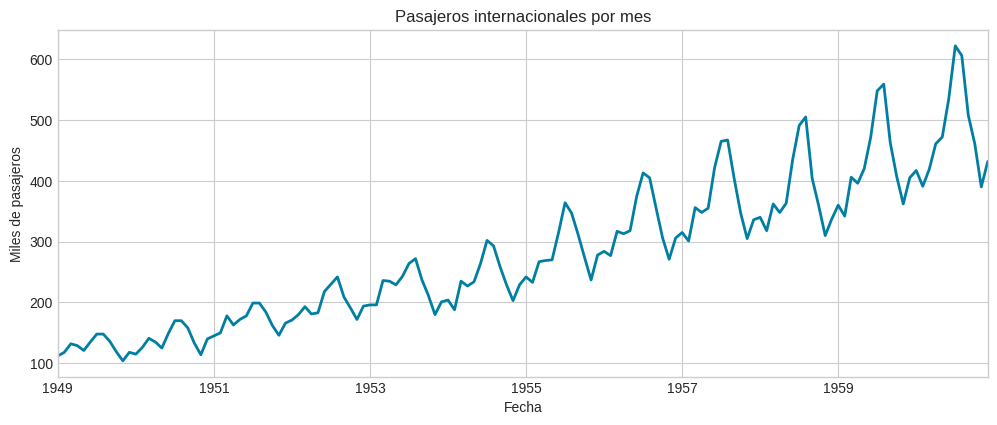

,mean,min,max
Ene,241.800,112.000,417.000
Feb,235.000,118.000,391.000
Mar,270.200,132.000,419.000
Abr,267.100,129.000,461.000
May,271.800,121.000,472.000
Jun,311.700,135.000,535.000
Jul,351.300,148.000,622.000
Ago,351.100,148.000,606.000
Sep,302.400,136.000,508.000
Oct,266.600,119.000,461.000


In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.5))
serie.plot(ax=ax, color=AZUL, linewidth=2)
ax.set(title="Pasajeros internacionales por mes", xlabel="Fecha", ylabel="Miles de pasajeros")
plt.show()

tabla_mes = serie.groupby(serie.index.month).agg(["mean", "min", "max"])
tabla_mes.index = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
display(tabla_mes.round(1))

**Escribe tu interpretación.**

Describe tendencia, estacionalidad, amplitud y cualquier observación inusual.

La tendencia es que la serie pasa de aproximadamente 112 mil pasajeros en enero de 1949 a 432 mil en diciembre de 1960. A partir de 1955 el crecimiento se acelera. La estacionalidad tiene un patrón anual muy claro y estable, en julio y agosto hay picos y en enero, febrero y noviembre son los valles. La amplitud es de entre 120 a 150 mil pasajeros. Lo notorio es que la amplitud crece con el nivel, los mínimos de 1949 son 112 y los de 1960 son 417; los máximos van de 148 a 622. El crecimiento que se acelera a partir de 1955 es notorio.

# 2. El periodo estacional m

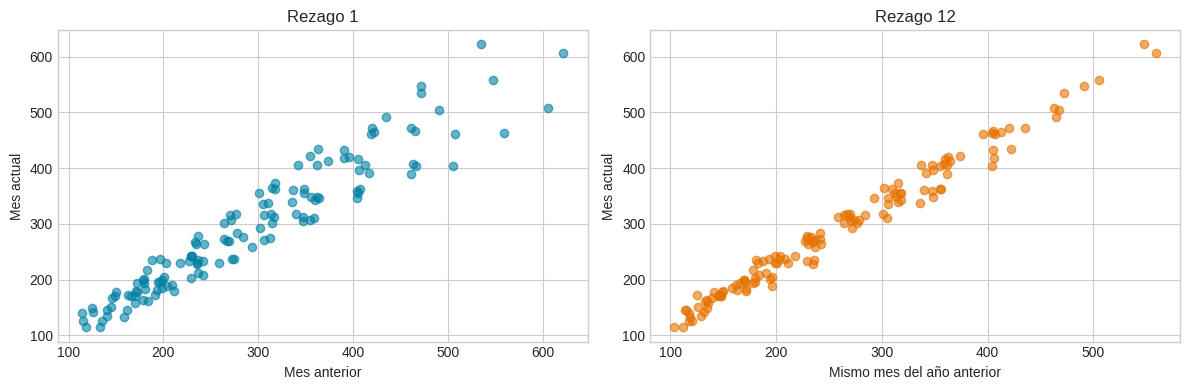

Correlación lag 1: 0.954
Correlación lag 12: 0.991


In [ ]:
M = 12
rezagos = pd.DataFrame({
    "actual": serie,
    "mes_anterior_lag_1": serie.shift(1),
    "mismo_mes_anio_anterior_lag_12": serie.shift(M),
}).dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(rezagos["mes_anterior_lag_1"], rezagos["actual"], alpha=.60, color=AZUL)
ax[0].set(title="Rezago 1", xlabel="Mes anterior", ylabel="Mes actual")
ax[1].scatter(rezagos["mismo_mes_anio_anterior_lag_12"], rezagos["actual"], alpha=.60, color=NARANJA)
ax[1].set(title="Rezago 12", xlabel="Mismo mes del año anterior", ylabel="Mes actual")
plt.tight_layout(); plt.show()

print("Correlación lag 1:", round(rezagos[["actual","mes_anterior_lag_1"]].corr().iloc[0,1], 3))
print("Correlación lag 12:", round(rezagos[["actual","mismo_mes_anio_anterior_lag_12"]].corr().iloc[0,1], 3))

En una serie mensual con ciclo anual, `m=12`. Esto no significa que el modelo use doce parámetros. Significa que una vuelta completa del patrón contiene doce observaciones.

- Datos diarios con ciclo semanal: `m=7`.
- Datos trimestrales con ciclo anual: `m=4`.
- Datos mensuales con ciclo anual: `m=12`.

El valor de `m` proviene del contexto y de la frecuencia de los datos; no debe elegirse solo porque una gráfica se vea mejor.

# 3. Diferencia regular y diferencia estacional

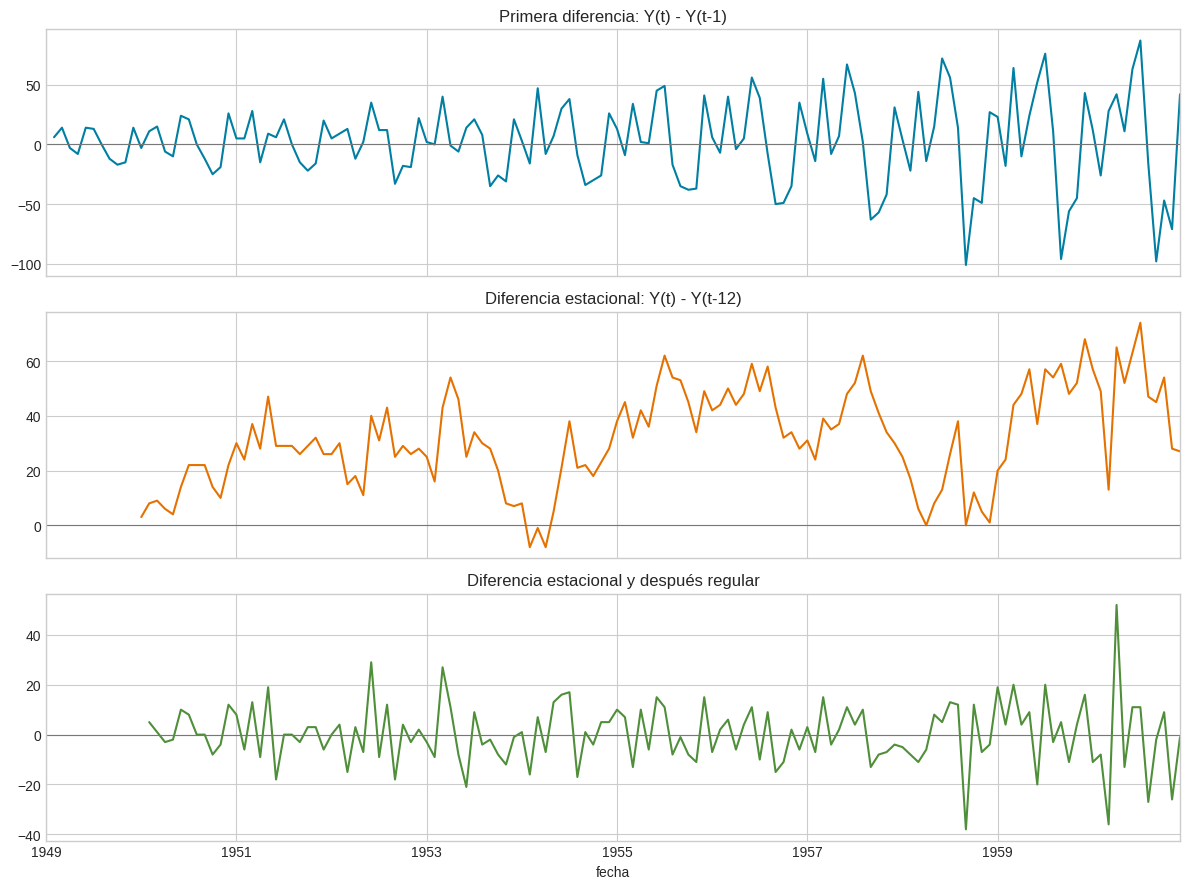

In [ ]:
diferencia_regular = serie.diff(1)
diferencia_estacional = serie.diff(12)
doble_diferencia = serie.diff(12).diff(1)

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
diferencia_regular.plot(ax=ax[0], color=AZUL, title="Primera diferencia: Y(t) - Y(t-1)")
diferencia_estacional.plot(ax=ax[1], color=NARANJA, title="Diferencia estacional: Y(t) - Y(t-12)")
doble_diferencia.plot(ax=ax[2], color=VERDE, title="Diferencia estacional y después regular")
for a in ax: a.axhline(0, color="#777777", linewidth=.8)
plt.tight_layout(); plt.show()

**Explica con tus palabras.**

¿Qué patrón elimina la diferencia estacional y qué cambia al aplicar después la diferencia regular?

La diferencia estacional elimina el patrón anual, porque compara cada mes con el mismo mes del año anterior. Al aplicar después la diferencia regular se elimina la tendencia residual, ya que el resultado es una serie centrada en cero.

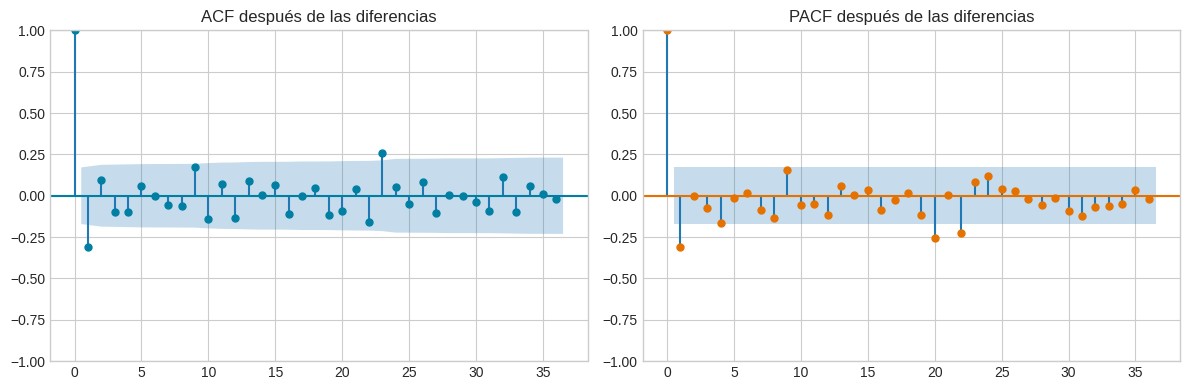

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(doble_diferencia.dropna(), lags=36, ax=ax[0], color=AZUL)
plot_pacf(doble_diferencia.dropna(), lags=36, ax=ax[1], method="ywm", color=NARANJA)
ax[0].set_title("ACF después de las diferencias")
ax[1].set_title("PACF después de las diferencias")
plt.tight_layout(); plt.show()

# 4. Lectura de SARIMA

La notación completa es:

`SARIMA(p,d,q)(P,D,Q,m)`

| Símbolo | Parte | Pregunta sencilla |
|---|---|---|
| `p` | AR regular | ¿Cuántos periodos recientes ayudan directamente? |
| `d` | Diferencia regular | ¿Cuántas veces se transforma el nivel en cambio reciente? |
| `q` | MA regular | ¿Cuántos errores recientes ayudan a corregir el pronóstico? |
| `P` | AR estacional | ¿Ayuda el valor de temporadas anteriores? |
| `D` | Diferencia estacional | ¿Se compara cada periodo con el mismo periodo del ciclo anterior? |
| `Q` | MA estacional | ¿Ayudan los errores de temporadas anteriores? |
| `m` | Periodicidad | ¿Cuántas observaciones forman un ciclo completo? |

Ejemplo: `SARIMA(0,1,1)(0,1,1,12)` usa una diferencia regular, una diferencia anual, un término MA reciente y un término MA anual.

# 5. Separación temporal

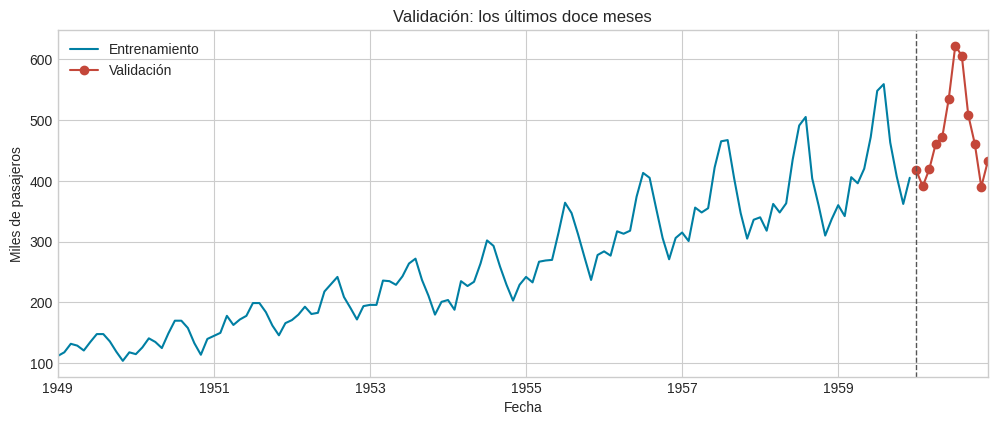

In [ ]:
HORIZONTE = 12
entrenamiento = serie.iloc[:-HORIZONTE]
validacion = serie.iloc[-HORIZONTE:]

fig, ax = plt.subplots(figsize=(12, 4.5))
entrenamiento.plot(ax=ax, color=AZUL, label="Entrenamiento")
validacion.plot(ax=ax, color=ROJO, marker="o", label="Validación")
ax.axvline(validacion.index[0], color="#555555", linestyle="--", linewidth=1)
ax.set(title="Validación: los últimos doce meses", xlabel="Fecha", ylabel="Miles de pasajeros")
ax.legend(); plt.show()

La validación representa la decisión real: con datos disponibles hasta diciembre de 1959, pronosticamos los doce meses de 1960. Todos los métodos compiten en exactamente los mismos meses.

# 6. Modelos candidatos

In [ ]:
pronosticos = {}

# 1. Referencia sencilla
pronosticos["Ingenuo estacional"] = ingenuo_estacional(entrenamiento, validacion.index, m=12)

# 2. Método de suavizamiento ya estudiado
ajuste_hw = ExponentialSmoothing(
    entrenamiento,
    trend="add",
    seasonal="mul",
    seasonal_periods=12,
    initialization_method="estimated",
).fit(optimized=True)
pronosticos["Holt-Winters multiplicativo"] = ajuste_hw.forecast(HORIZONTE)

# La amplitud aumenta con el nivel. El logaritmo permite trabajar con cambios proporcionales.
log_entrenamiento = np.log(entrenamiento)

# 3. ARIMA sin componente estacional
ajuste_arima = SARIMAX(
    log_entrenamiento,
    order=(1,1,1),
    seasonal_order=(0,0,0,0),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)
pronosticos["ARIMA(1,1,1) + log"] = np.exp(ajuste_arima.forecast(HORIZONTE))

# 4 y 5. Dos candidatos SARIMA deliberadamente pequeños
candidatos_sarima = {
    "SARIMA(0,1,1)(0,1,1,12) + log": ((0,1,1), (0,1,1,12)),
    "SARIMA(1,1,0)(0,1,1,12) + log": ((1,1,0), (0,1,1,12)),
}
ajustes_sarima = {}
for nombre, (orden, orden_estacional) in candidatos_sarima.items():
    ajuste = SARIMAX(
        log_entrenamiento,
        order=orden,
        seasonal_order=orden_estacional,
        trend="n",
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)
    ajustes_sarima[nombre] = ajuste
    pronosticos[nombre] = np.exp(ajuste.forecast(HORIZONTE))

,ME,MAE,RMSE,sMAPE_%
Holt-Winters multiplicativo,-4.783,10.303,15.810,2.163
"SARIMA(0,1,1)(0,1,1,12) + log",-12.006,13.158,18.494,2.799
"SARIMA(1,1,0)(0,1,1,12) + log",-13.823,14.673,19.746,3.104
Ingenuo estacional,47.833,47.833,50.708,10.572
"ARIMA(1,1,1) + log",59.542,68.475,95.518,14.314


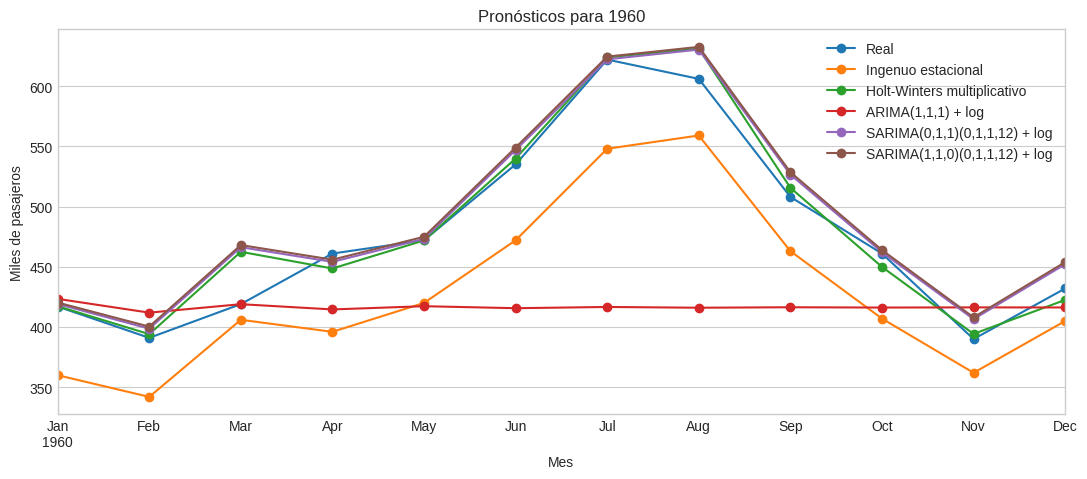

In [ ]:
resultados = pd.DataFrame({
    nombre: metricas(validacion, pronostico)
    for nombre, pronostico in pronosticos.items()
}).T.sort_values("MAE")
display(resultados.round(3))

comparacion = pd.DataFrame({"Real": validacion, **pronosticos})
ax = comparacion.plot(figsize=(13, 5), marker="o")
ax.set(title="Pronósticos para 1960", xlabel="Mes", ylabel="Miles de pasajeros")
plt.show()

**Antes de elegir.**

¿Qué modelo logra el menor MAE? ¿SARIMA mejora al ARIMA no estacional? ¿Supera también a Holt-Winters?

El menor MAE lo logra Holt-Winters multiplicativo, con 10.303. SARIMA sí mejora el ARIMA no estacional ARIMA(1,1,1)+log tiene un MAE de 68.475 y los dos SARIMA bajan a 13.158 y 14.673, así que la componente estacional es decisiva. SARIMA no supera a Holt-Winters, en realidad, gana por MAE con 10.3 contra 13.2, aunque ambos sobreestiman ligeramente.

### Por qué AIC no decide por sí solo

AIC ayuda a comparar modelos ajustados sobre la misma variable y con el mismo tratamiento de diferenciación. La validación responde una pregunta distinta: cuál pronosticó mejor observaciones posteriores.

En esta práctica elegimos con el error de validación y utilizamos AIC como evidencia complementaria entre candidatos comparables.

In [ ]:
tabla_aic = pd.DataFrame({
    nombre: {"AIC": ajuste.aic, "BIC": ajuste.bic}
    for nombre, ajuste in ajustes_sarima.items()
}).T.sort_values("AIC")
display(tabla_aic.round(3))

,AIC,BIC
"SARIMA(1,1,0)(0,1,1,12) + log",-396.700,-388.710
"SARIMA(0,1,1)(0,1,1,12) + log",-392.992,-385.030


# 7. Diagnóstico del SARIMA

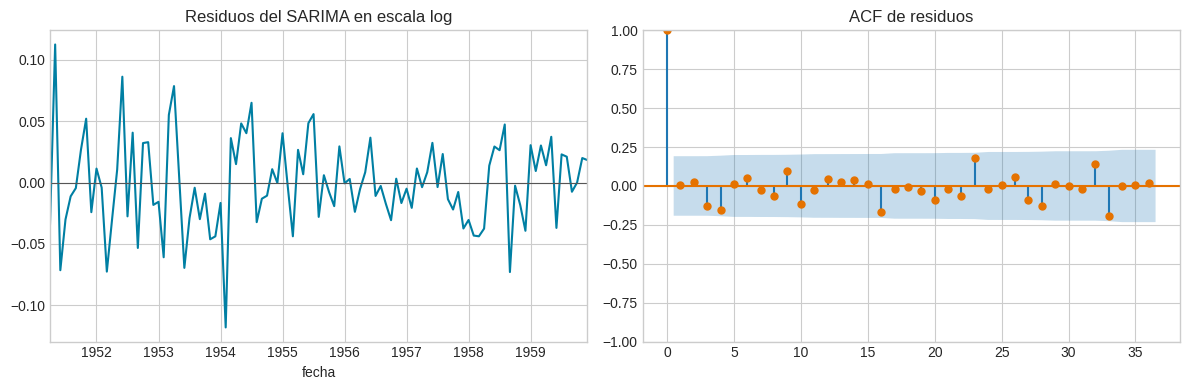

,lb_stat,lb_pvalue
12,8.454,0.585
24,18.692,0.664


In [ ]:
nombre_sarima = "SARIMA(0,1,1)(0,1,1,12) + log"
ajuste_sarima = ajustes_sarima[nombre_sarima]

# Se descartan los residuos iniciales afectados por la inicialización del modelo.
inicio_util = max(ajuste_sarima.loglikelihood_burn, 13)
residuos = ajuste_sarima.resid.iloc[inicio_util:].dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
residuos.plot(ax=ax[0], color=AZUL)
ax[0].axhline(0, color="#555555", linewidth=.8)
ax[0].set_title("Residuos del SARIMA en escala log")
plot_acf(residuos, lags=36, ax=ax[1], color=NARANJA)
ax[1].set_title("ACF de residuos")
plt.tight_layout(); plt.show()

diagnostico = acorr_ljungbox(residuos, lags=[12,24], model_df=2, return_df=True)
display(diagnostico.round(4))

**Interpreta el diagnóstico.**

¿Quedó autocorrelación visible? ¿Qué indican los p-valores de Ljung-Box?

No quedó autocorrelación visible, porque la ACF de los residuos no muestra barras significativas fuera de las bandas. Los p-valores de Ljung-Box son p = 0.585 (lag 12) y p = 0.664 (lag 24), ambos mayores que 0.05. No se rechaza la hipótesis de ausencia de autocorrelación. Podemos concluir que el modelo capturó la dinámica regular y estacional.

# 8. Incertidumbre del pronóstico

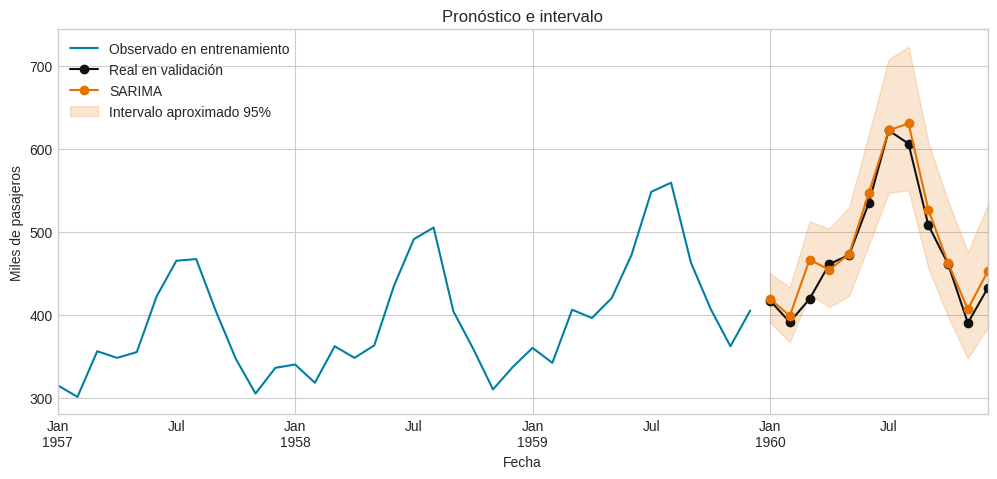

In [ ]:
pred = ajuste_sarima.get_forecast(steps=HORIZONTE)
media = np.exp(pred.predicted_mean)
intervalo = np.exp(pred.conf_int(alpha=.05))

fig, ax = plt.subplots(figsize=(12, 5))
entrenamiento.iloc[-36:].plot(ax=ax, color=AZUL, label="Observado en entrenamiento")
validacion.plot(ax=ax, color="#111111", marker="o", label="Real en validación")
media.plot(ax=ax, color=NARANJA, marker="o", label="SARIMA")
ax.fill_between(intervalo.index, intervalo.iloc[:,0], intervalo.iloc[:,1], color=NARANJA, alpha=.18, label="Intervalo aproximado 95%")
ax.set(title="Pronóstico e intervalo", xlabel="Fecha", ylabel="Miles de pasajeros")
ax.legend(); plt.show()

El intervalo expresa incertidumbre bajo los supuestos del modelo. No garantiza que el valor real quede dentro y tampoco incorpora automáticamente crisis, cambios regulatorios o información externa.

# 9. Ficha de decisión

Entrega una página con:

1. **Problema y datos.** Variable, frecuencia, periodo y horizonte.
2. **Estacionalidad.** Evidencia del ciclo y justificación de `m`.
3. **Transformaciones.** Uso o rechazo de logaritmo, diferencia regular y diferencia estacional.
4. **Comparación.** Tabla de métricas y referente.
5. **Diagnóstico.** Qué indican residuos y Ljung-Box.
6. **Decisión.** Modelo elegido, utilidad y principal limitación.

Plantilla breve:

> Para pronosticar __________ a un horizonte de __________ utilizamos `m=____` porque __________. El modelo seleccionado fue __________, con un MAE de __________. Frente al referente __________. Los residuos indican __________. Esta decisión sería útil para __________, pero no incorpora __________.

Para pronosticar los pasajeros internacionales mensuales (miles) a un horizonte de 12 meses utilizamos m = 12 porque la serie tiene un ciclo anual claro, el patrón se repite cada 12 meses y la evidencia gráfica y de correlación (lag 12 = 0.991 vs lag 1 = 0.954) lo confirma. El modelo seleccionado fue SARIMA(0,1,1)(0,1,1,12) con transformación logarítmica, con un MAE de 13.158. Frente al referente ingenuo estacional (MAE = 47.833) y al ARIMA no estacional (MAE = 68.475), SARIMA mejora sustancialmente; sin embargo, Holt-Winters multiplicativo obtuvo mejor MAE (10.303) en esta validación. Los residuos indican ruido blanco, sin autocorrelación visible y Ljung-Box con p = 0.585 y 0.664, por lo que no se rechaza la ausencia de autocorrelación. Esta decisión sería útil para planificar capacidad, personal y presupuesto con un año de anticipación, pero no toma en cuenta eventos externos como crisis económicas, cambios regulatorios, pandemias, ni cambios estructurales en el mercado aéreo.

### Rúbrica común

| Evidencia | Puntos |
|---|---:|
| Problema, frecuencia, horizonte y variable | 15 |
| Estacionalidad y elección de `m` | 20 |
| Transformaciones y candidatos justificados | 20 |
| Validación, métricas y referencia | 25 |
| Residuos, decisión y limitación | 20 |

### Fuentes de consulta

- Hyndman, R. J. y Athanasopoulos, G. *Forecasting: Principles and Practice*, sección de ARIMA estacional: https://otexts.com/fpp3/arima.html
- Documentación de `SARIMAX` en statsmodels: https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html
- Documentación del conjunto `AirPassengers`: https://search.r-project.org/R/refmans/datasets/html/AirPassengers.html